In [1]:
import glob
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer as pc
import pystac_client
import odc.stac
from rasterio import features
from scipy import ndimage

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

CORTE = "10-20"          # comparamos cada año del 1 de enero al 20 de octubre
FIG = "figuras"

/Users/hidekiharada/Python/Python/Ejercicio/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 1 · Los datos de focos

Las descargas están en `descargar_datos.sh`. FIRMS trae una fila por foco con `type`:
0 = vegetación probable, 1 = volcán, 2 = otra fuente fija, 3 = mar. INPE no trae `type`,
así que para comparar igual con igual usamos **todos** los focos en ambos y luego probamos
quitar las fuentes fijas de FIRMS como robustez.

In [2]:
deptos = gpd.read_file("datos/departamentos.geojson")[["NOMBDEP", "geometry"]].to_crs(4326)

firms = pd.concat(
    pd.read_csv(f, usecols=["latitude", "longitude", "acq_date", "type"])
    for f in sorted(glob.glob("datos/firms/viirs-snpp_*_Peru.csv"))
).rename(columns={"latitude": "lat", "longitude": "lon", "acq_date": "fecha"})
firms["fuente"] = "FIRMS"

inpe = pd.read_csv("datos/inpe_peru_npp_2026.csv")
inpe = inpe.assign(fecha=inpe.data_hora_gmt.str[:10], type=np.nan, fuente="INPE")[
    ["lat", "lon", "fecha", "type", "fuente"]]

focos = pd.concat([firms, inpe], ignore_index=True)
focos["anio"] = focos.fecha.str[:4].astype(int)
focos = gpd.GeoDataFrame(focos, geometry=gpd.points_from_xy(focos.lon, focos.lat), crs=4326)
focos = gpd.sjoin(focos, deptos, predicate="within").drop(columns="index_right")

print(f"{len(focos):,} focos dentro del Perú")
print(focos.groupby(["anio", "fuente"]).size().unstack().fillna(0).astype(int).T.to_string())

1,095,640 focos dentro del Perú
anio     2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025   2026
fuente                                                                                                         
FIRMS   80423  64352  57577  69854  90895  56895  62954  74089  98121  67103  89311  78995  99296  53451      0
INPE        0      0      0      0      0      0      0      0      0      0      0      0      0      0  52324


## 2 · Calibración: ¿INPE cuenta lo mismo que FIRMS?

Si 2026 viene de otra fuente, un «récord» podría ser solo un cambio de fuente. FIRMS publica
sin clave los últimos 7 días (`South America 7d`), así que comparamos día por día.

In [3]:
f7 = pd.read_csv("datos/firms/SUOMI_VIIRS_C2_South_America_7d.csv",
                 usecols=["latitude", "longitude", "acq_date"])
f7 = gpd.GeoDataFrame(f7, geometry=gpd.points_from_xy(f7.longitude, f7.latitude), crs=4326)
f7 = gpd.sjoin(f7, deptos, predicate="within")

dias = sorted(set(f7.acq_date) & set(inpe.fecha))
foc26 = focos[focos.fuente == "INPE"]
calib = pd.DataFrame({
    "FIRMS": f7.groupby("acq_date").size().reindex(dias),
    "INPE": foc26.groupby("fecha").size().reindex(dias),
}).fillna(0).astype(int)
calib["dif_%"] = 100 * (calib.INPE / calib.FIRMS - 1)
total_dif = 100 * (calib.INPE.sum() / calib.FIRMS.sum() - 1)
print(calib.to_string())
print(f"\ntotal de los {len(dias)} días: INPE {calib.INPE.sum():,} vs FIRMS {calib.FIRMS.sum():,} "
      f"-> diferencia {total_dif:+.1f} %")

            FIRMS  INPE  dif_%
2026-10-14    464   592   27.6
2026-10-15    763   881   15.5
2026-10-16   1385  1465    5.8
2026-10-17    176   188    6.8
2026-10-18    263   285    8.4
2026-10-19    212   250   17.9
2026-10-20     84    89    6.0

total de los 7 días: INPE 3,750 vs FIRMS 3,347 -> diferencia +12.0 %


## 3 · ¿Octubre récord? Mismo mes, año a año

Comparamos siempre la **misma ventana: 1–20 de octubre** (2026 llega hasta el 20), el pico de
la temporada. Comparar años completos mezclaría temporadas distintas.

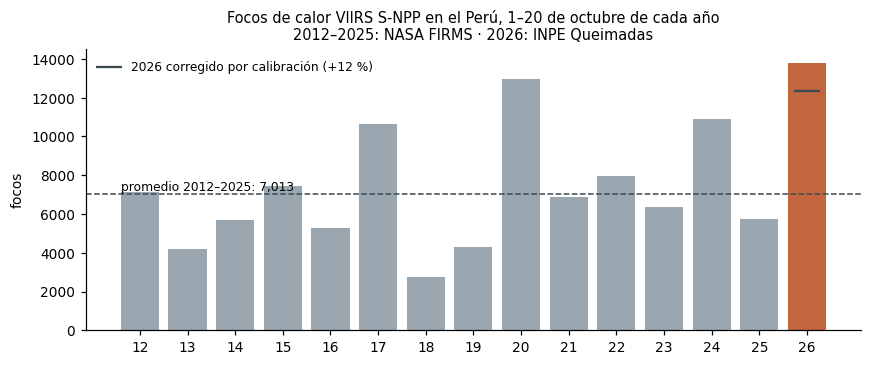

anio
2012     7112
2013     4191
2014     5697
2015     7452
2016     5277
2017    10637
2018     2760
2019     4282
2020    12967
2021     6852
2022     7973
2023     6362
2024    10890
2025     5733
2026    13809

octubre 2026: 13,809 focos (+97 % frente al promedio) | puesto 1 de 15 | máximo previo 12,967 (2020)
corregido por calibración: 12,325 -> ya NO es récord


In [4]:
octubre = focos[(focos.fecha.str[5:7] == "10") & (focos.fecha.str[8:] <= CORTE[3:])].copy()
oct_anio = octubre.groupby("anio").size()
historia = oct_anio.loc[2012:2025]

# INPE cuenta más que FIRMS (sección 2): versión de 2026 corregida por esa diferencia
factor = 1 + total_dif / 100
oct_corr = oct_anio[2026] / factor
rk = oct_anio.rank(ascending=False).astype(int)

fig, ax = plt.subplots(figsize=(8, 3.4))
colores = ["#c1663f" if a == 2026 else "#9aa7b0" for a in oct_anio.index]
ax.bar(oct_anio.index, oct_anio.values, color=colores)
ax.scatter([2026], [oct_corr], marker="_", s=300, color="#3c4a52", zorder=3,
           label=f"2026 corregido por calibración ({total_dif:+.0f} %)")
ax.axhline(historia.mean(), color="#3c4a52", lw=1, ls="--")
ax.text(2011.6, historia.mean() * 1.03, f"promedio 2012–2025: {historia.mean():,.0f}", fontsize=8)
ax.set_title("Focos de calor VIIRS S-NPP en el Perú, 1–20 de octubre de cada año\n"
             "2012–2025: NASA FIRMS · 2026: INPE Queimadas", fontsize=9.5)
ax.set_ylabel("focos")
ax.set_xticks(oct_anio.index, [str(a)[2:] for a in oct_anio.index])
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG}/focos_octubre_por_anio.png", bbox_inches="tight")
plt.show()

print(oct_anio.to_string())
print(f"\noctubre 2026: {oct_anio[2026]:,} focos ({100 * (oct_anio[2026] / historia.mean() - 1):+.0f} % "
      f"frente al promedio) | puesto {rk[2026]} de {len(rk)} | máximo previo {historia.max():,} "
      f"({historia.idxmax()})")
print(f"corregido por calibración: {oct_corr:,.0f} -> "
      f"{'sigue' if oct_corr > historia.max() else 'ya NO es'} récord")

### Por distrito: cada distrito contra su propia historia

La pregunta no es qué distrito tiene más focos (los grandes y amazónicos siempre ganan), sino
**si a cada distrito le fue peor que en sus propios octubres de 2012–2025**. Para cada uno:
promedio y máximo de sus octubres previos, y `log(1 + focos 2026) − log(1 + promedio)`
(+0,69 = el doble). Como en el monitor de referencia, si el promedio es muy bajo (< 10 focos)
la comparación no es confiable y se marca «n. d.».

In [5]:
distritos = gpd.read_file("datos/distritos.geojson").to_crs(4326)
distritos["ubigeo"] = distritos.IDDIST
octubre = gpd.sjoin(octubre.drop(columns="NOMBDEP"),
                    distritos[["ubigeo", "NOMBDIST", "NOMBPROV", "NOMBDEP", "geometry"]],
                    predicate="within").drop(columns="index_right")

MIN_PROM = 10
tab = (octubre.groupby(["ubigeo", "anio"]).size().unstack(fill_value=0)
       .reindex(index=distritos.ubigeo, columns=range(2012, 2027), fill_value=0))
dist = distritos.set_index("ubigeo")[["NOMBDIST", "NOMBPROV", "NOMBDEP"]].copy()
dist["oct_2026"] = tab[2026]
dist["prom_2012_25"] = tab.loc[:, 2012:2025].mean(axis=1)
dist["max_previo"] = tab.loc[:, 2012:2025].max(axis=1)
dist["anio_max"] = tab.loc[:, 2012:2025].idxmax(axis=1)
dist["log_dif"] = np.log1p(dist.oct_2026) - np.log1p(dist.prom_2012_25)
dist["comparable"] = dist.prom_2012_25 >= MIN_PROM
dist["record"] = dist.comparable & (dist.oct_2026 > dist.max_previo)
dist["record_corregido"] = dist.comparable & (dist.oct_2026 / factor > dist.max_previo)

comp = dist[dist.comparable]
print(f"distritos con historia suficiente (promedio ≥ {MIN_PROM}): {len(comp)} de {len(dist)}")
print(f"  con más focos que su promedio : {(comp.log_dif > 0).sum()} ({(comp.log_dif > 0).mean():.0%})")
print(f"  al menos el doble (log ≥ 0,69): {(comp.log_dif >= np.log(2)).sum()}")
print(f"  récord propio                 : {comp.record.sum()} (corregido: {comp.record_corregido.sum()})")
print(f"  mediana de log_dif            : {comp.log_dif.median():+.2f}")
comp.sort_values("log_dif", ascending=False).head(15)

distritos con historia suficiente (promedio ≥ 10): 108 de 1834
  con más focos que su promedio : 54 (50%)
  al menos el doble (log ≥ 0,69): 15
  récord propio                 : 9 (corregido: 8)
  mediana de log_dif            : +0.00


,NOMBDIST,NOMBPROV,NOMBDEP,oct_2026,prom_2012_25,max_previo,anio_max,log_dif,comparable,record,record_corregido
ubigeo,,,,,,,,,,,
030104,CURAHUASI,ABANCAY,APURIMAC,369,18.2,103,2022,3.0,True,True,True
220101,MOYOBAMBA,MOYOBAMBA,SAN MARTIN,120,16.3,35,2021,1.9,True,True,True
250107,MANANTAY,CORONEL PORTILLO,UCAYALI,170,31.6,133,2024,1.7,True,True,True
250105,YARINACOCHA,CORONEL PORTILLO,UCAYALI,134,27.4,65,2023,1.6,True,True,True
250203,TAHUANIA,ATALAYA,UCAYALI,293,80.4,368,2020,1.3,True,False,False
250106,NUEVA REQUENA,CORONEL PORTILLO,UCAYALI,446,130.6,380,2023,1.2,True,True,True
120608,RIO TAMBO,SATIPO,JUNIN,335,125.5,277,2020,1.0,True,True,True
010701,BAGUA GRANDE,UTCUBAMBA,AMAZONAS,59,22.9,39,2022,0.9,True,True,True
160603,PADRE MARQUEZ,UCAYALI,LORETO,111,44.9,133,2023,0.9,True,False,False


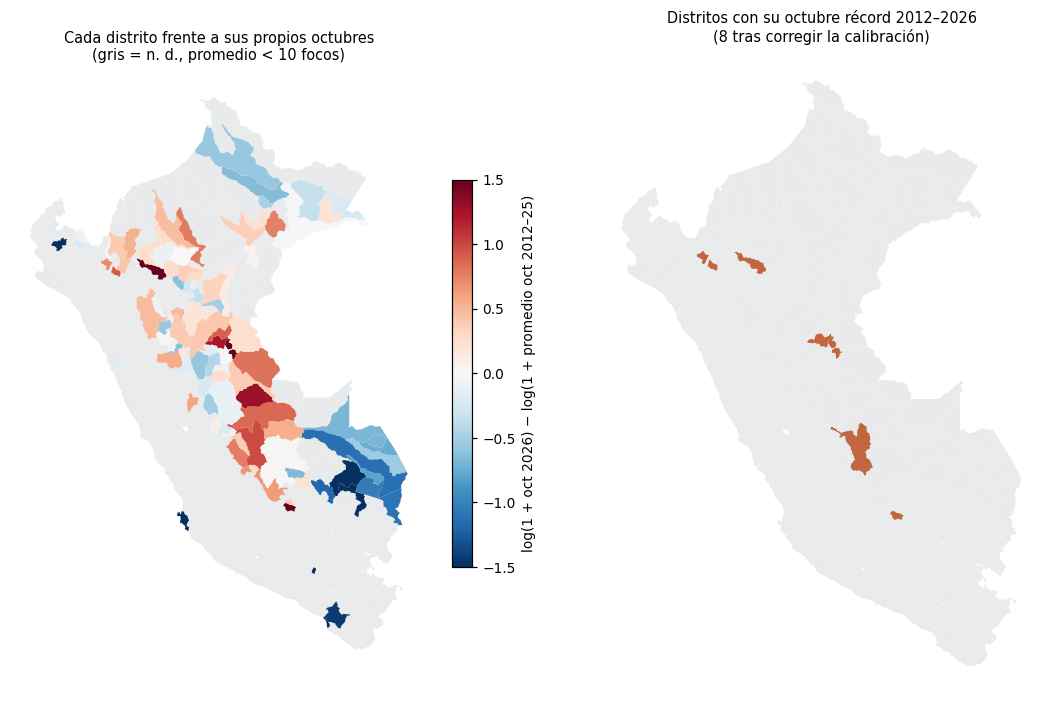

In [6]:
mapa = distritos.merge(dist.reset_index()[["ubigeo", "log_dif", "comparable", "record_corregido"]], on="ubigeo")
fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 6.5))
mapa[~mapa.comparable].plot(color="#e8eaec", ax=izq, lw=0)
mapa[mapa.comparable].plot(column="log_dif", cmap="RdBu_r", vmin=-1.5, vmax=1.5, ax=izq, lw=0,
                           legend=True, legend_kwds={"label": "log(1 + oct 2026) − log(1 + promedio oct 2012–25)",
                                                     "shrink": 0.6})
izq.set_title("Cada distrito frente a sus propios octubres\n(gris = n. d., promedio < 10 focos)", fontsize=9.5)
izq.axis("off")
mapa.plot(color="#e8eaec", ax=der, lw=0)
mapa[mapa.record_corregido].plot(color="#c1663f", ax=der, lw=0)
der.set_title(f"Distritos con su octubre récord 2012–2026\n"
              f"({mapa.record_corregido.sum()} tras corregir la calibración)", fontsize=9.5)
der.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG}/mapa_distritos.png", bbox_inches="tight")
plt.show()

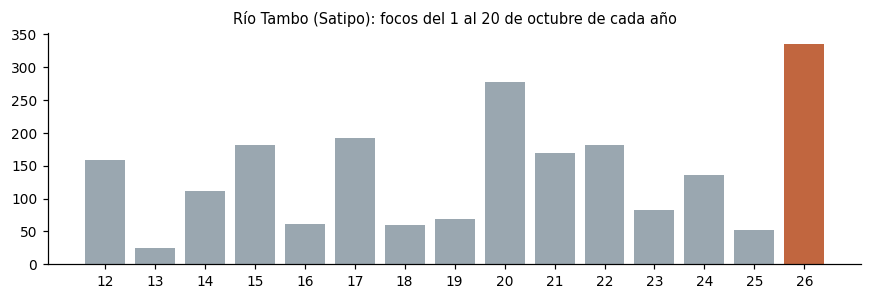

anio
2012    159
2013     25
2014    112
2015    182
2016     62
2017    192
2018     59
2019     69
2020    277
2021    169
2022    182
2023     82
2024    135
2025     52
2026    335


In [7]:
# Río Tambo, el distrito del incendio que medimos abajo, en su propia serie de octubres
rt_serie = tab.loc[dist.index[(dist.NOMBDIST == "RIO TAMBO") & (dist.NOMBPROV == "SATIPO")][0]]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(rt_serie.index, rt_serie.values, color=["#c1663f" if a == 2026 else "#9aa7b0" for a in rt_serie.index])
ax.set_title("Río Tambo (Satipo): focos del 1 al 20 de octubre de cada año", fontsize=9.5)
ax.set_xticks(rt_serie.index, [str(a)[2:] for a in rt_serie.index])
plt.tight_layout()
plt.savefig(f"{FIG}/rio_tambo_octubres.png", bbox_inches="tight")
plt.show()
print(rt_serie.to_string())

**Robustez.** FIRMS marca algunos focos como fuentes fijas o volcanes (`type` 1–3). INPE no
los marca, así que no podemos quitarlos en 2026. ¿Cuánto pesan en la historia?

In [8]:
hist = octubre[octubre.fuente == "FIRMS"]
peso_fijas = 100 * (hist["type"] != 0).mean()   # ojo: hist.type es el tipo de geometría
print(f"focos FIRMS de octubre 2012–2025 que no son vegetación (type≠0): {peso_fijas:.1f} %")

focos FIRMS de octubre 2012–2025 que no son vegetación (type≠0): 1.4 %


## 4 · El incendio de Río Tambo con dNBR

**Zona.** El distrito de Río Tambo (Satipo, Junín) mide más de 10 000 km². Los focos de octubre
se concentran cerca de −11,87° / −73,86°, así que trabajamos en un recuadro de ~30 × 29 km
alrededor de ese grupo.

**Fechas.** La nubosidad de una escena entera no sirve: lo que importa es la nube **dentro de la
zona**. La medimos con la capa SCL antes de elegir.

In [9]:
BBOX = [-74.0, -12.0, -73.72, -11.74]
rio_tambo = distritos[(distritos.NOMBDIST == "RIO TAMBO") & (distritos.NOMBPROV == "SATIPO")]

f_zona = focos.cx[BBOX[0]:BBOX[2], BBOX[1]:BBOX[3]]
f_zona = f_zona[f_zona.anio == 2026]
print("focos 2026 en la zona, por día (sep–oct):")
print(f_zona[f_zona.fecha >= "2026-09-01"].groupby("fecha").size().to_string())

focos 2026 en la zona, por día (sep–oct):
fecha
2026-09-03     2
2026-09-04     3
2026-09-05     4
2026-09-09     5
2026-09-10     3
2026-09-13     3
2026-09-20     6
2026-09-21     6
2026-09-24     4
2026-09-25     4
2026-10-01     6
2026-10-02     2
2026-10-04    10
2026-10-05    29
2026-10-06    20
2026-10-07     7
2026-10-08     4
2026-10-09    16
2026-10-10     8
2026-10-11     1
2026-10-13    22
2026-10-14    33
2026-10-15    24
2026-10-16    27
2026-10-17     1
2026-10-19     9
2026-10-20    15


In [10]:
cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                modifier=pc.sign_inplace)
items = cat.search(collections=["sentinel-2-l2a"], bbox=BBOX,
                   datetime="2026-08-25/2026-10-21").item_collection()
scl = odc.stac.load(items, bands=["SCL"], bbox=BBOX, resolution=20, crs="EPSG:32718",
                    groupby="solar_day").SCL

NUBES = [3, 8, 9, 10]            # sombra, nube media, nube alta, cirro
nubes = pd.DataFrame({
    "fecha": [str(t)[:10] for t in scl.time.values],
    "nubes_zona_%": [100 * np.isin(scl.sel(time=t).values, NUBES).mean() for t in scl.time.values],
})
nubes

,fecha,nubes_zona_%
0,2026-08-29,7.2
1,2026-08-31,13.9
2,2026-09-03,7.0
3,2026-09-08,100.0
4,2026-09-10,34.4
5,2026-09-13,4.3
6,2026-09-18,99.9
7,2026-09-20,9.0
8,2026-09-23,6.9
9,2026-09-28,18.2


Elegimos:
- **Antes: 23 sep 2026** (6,9 % de nubes en la zona), antes del salto de focos del 4 oct.
- **Después: 8 oct 2026** (2,3 % de nubes), la imagen más limpia tras el inicio del fuego.
- **Sensibilidad: 13 oct 2026** (30 % de nubes), que capta el crecimiento posterior.

In [11]:
ANTES, DESPUES, DESPUES_2 = "2026-09-23", "2026-10-08", "2026-10-13"

def cargar(fecha):
    sel = [i for i in items if i.datetime.strftime("%Y-%m-%d") == fecha]
    ds = odc.stac.load(sel, bands=["B04", "B08", "B12", "SCL"], bbox=BBOX, resolution=20,
                       crs="EPSG:32718", groupby="solar_day").isel(time=0)
    # desde la línea base 04.00 (2022) los niveles digitales traen un desfase de +1000
    refl = {b: (ds[b].astype("float32") - 1000) / 10000 for b in ["B04", "B08", "B12"]}
    valido = ~np.isin(ds.SCL.values, [0, 1, 3, 6, 8, 9, 10, 11])   # sin datos, nube, agua, nieve
    nbr = (refl["B08"] - refl["B12"]) / (refl["B08"] + refl["B12"])
    return ds, refl, nbr.values, valido

ds0, r0, nbr0, ok0 = cargar(ANTES)
ds1, r1, nbr1, ok1 = cargar(DESPUES)
ds2, r2, nbr2, ok2 = cargar(DESPUES_2)

dnbr = np.where(ok0 & ok1, nbr0 - nbr1, np.nan)
dnbr2 = np.where(ok0 & ok2, nbr0 - nbr2, np.nan)
print(f"píxeles válidos en ambas fechas: {np.isfinite(dnbr).mean():.1%} (8 oct) | "
      f"{np.isfinite(dnbr2).mean():.1%} (13 oct)")

píxeles válidos en ambas fechas: 91.1% (8 oct) | 66.9% (13 oct)


**Severidad** con los umbrales USGS (Key y Benson): <0,10 no quemado; 0,10–0,27 baja;
0,27–0,44 moderada-baja; 0,44–0,66 moderada-alta; ≥0,66 alta. Un píxel de 20 m = 0,04 ha.

Un dNBR alto también aparece por cosechas, derrumbes o ríos que cambian de cauce. Por eso damos
además una versión **sembrada con focos**: solo cuentan las manchas de dNBR ≥ 0,27 que tienen
al menos un foco VIIRS de octubre dentro o a menos de 500 m.

In [12]:
HA = 20 * 20 / 1e4
CORTES = [0.10, 0.27, 0.44, 0.66]
NOMBRES = ["baja", "moderada-baja", "moderada-alta", "alta"]

def por_severidad(d):
    d = d[np.isfinite(d)]                      # sin esto, las nubes caerían en «alta»
    clases = np.digitize(d, CORTES)            # 0 = no quemado ... 4 = alta
    return pd.Series({n: (clases == i + 1).sum() * HA for i, n in enumerate(NOMBRES)})

# rejilla de focos en el mismo sistema que el raster
x, y = ds1.x.values, ds1.y.values
transform = ds1.odc.geobox.affine
pts = f_zona[(f_zona.fecha >= "2026-10-01")].to_crs(32718)

def sembrado(d, hasta):
    p = pts[pts.fecha <= hasta]
    semilla = features.rasterize(((g.buffer(500), 1) for g in p.geometry),
                                 out_shape=d.shape, transform=transform).astype(bool)
    etiquetas, _ = ndimage.label(np.nan_to_num(d) >= 0.27)
    vivas = np.unique(etiquetas[semilla & (etiquetas > 0)])
    return np.isin(etiquetas, vivas) & (etiquetas > 0)

quem1 = sembrado(dnbr, DESPUES)
quem2 = sembrado(dnbr2, DESPUES_2)

resumen = pd.DataFrame({
    f"{DESPUES} · toda la zona": por_severidad(dnbr),
    f"{DESPUES} · sembrado con focos": por_severidad(np.where(quem1, dnbr, np.nan)),
    f"{DESPUES_2} · sembrado con focos": por_severidad(np.where(quem2, dnbr2, np.nan)),
}).T
resumen["≥0,27 (ha)"] = resumen[NOMBRES[1:]].sum(axis=1)
resumen["≥0,10 (ha)"] = resumen[NOMBRES].sum(axis=1)
resumen["nubes post %"] = [nubes.set_index("fecha").loc[f, "nubes_zona_%"]
                           for f in [DESPUES, DESPUES, DESPUES_2]]
resumen.round(0)

,baja,moderada-baja,moderada-alta,alta,"≥0,27 (ha)","≥0,10 (ha)",nubes post %
2026-10-08 · toda la zona,"3,741.0",734.0,384.0,67.0,"1,185.0","4,926.0",2.0
2026-10-08 · sembrado con focos,0.0,372.0,294.0,45.0,711.0,711.0,2.0
2026-10-13 · sembrado con focos,0.0,796.0,690.0,123.0,"1,609.0","1,609.0",30.0


In [13]:
# ¿cuánto cae dentro del distrito de Río Tambo y en los vecinos?
cod = features.rasterize(((g, i + 1) for i, g in enumerate(distritos.to_crs(32718).geometry)),
                         out_shape=dnbr.shape, transform=transform)
ids, n = np.unique(cod[quem2], return_counts=True)     # al 13 oct
por_distrito = pd.DataFrame({
    "distrito": distritos.NOMBDIST.values[ids - 1],
    "provincia": distritos.NOMBPROV.values[ids - 1],
    "ha_quemadas": n * HA,
}).sort_values("ha_quemadas", ascending=False)
por_distrito

,distrito,provincia,ha_quemadas
2,RIO TAMBO,SATIPO,"1,560.6"
1,MAZAMARI,SATIPO,39.6
0,PANGOA,SATIPO,8.5


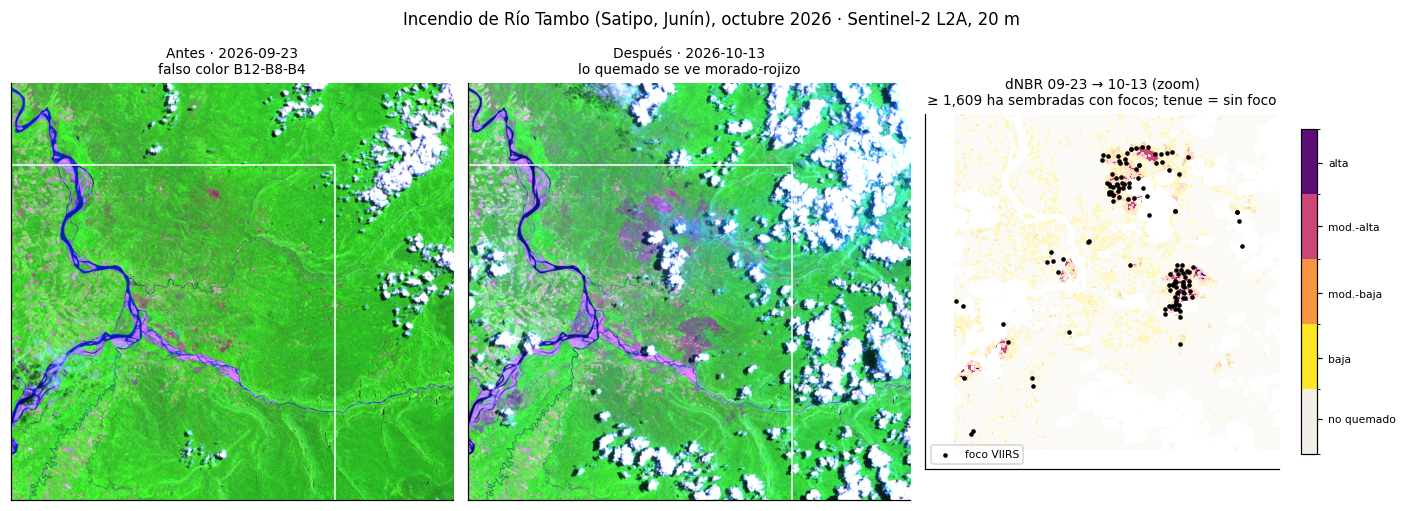

In [14]:
def falso_color(r):
    rgb = np.dstack([r["B12"].values, r["B08"].values, r["B04"].values])
    return np.clip(rgb / np.array([0.35, 0.45, 0.15]), 0, 1)

ext = [x.min(), x.max(), y.min(), y.max()]
# zoom: caja de los píxeles quemados (13 oct) más 2 km de margen
filas, cols = np.where(quem2)
zx = [x[cols].min() - 2000, x[cols].max() + 2000]
zy = [y[filas].min() - 2000, y[filas].max() + 2000]

from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap(["#f2f0e6", "#fde725", "#f89540", "#cc4778", "#5c0e74"])
norm = BoundaryNorm([-1] + CORTES + [2], cmap.N)

fig, ejes = plt.subplots(1, 3, figsize=(13, 4.8))
ejes[0].imshow(falso_color(r0), extent=ext)
ejes[0].set_title(f"Antes · {ANTES}\nfalso color B12-B8-B4", fontsize=9)
ejes[1].imshow(falso_color(r2), extent=ext)
ejes[1].set_title(f"Después · {DESPUES_2}\nlo quemado se ve morado-rojizo", fontsize=9)
ejes[2].imshow(dnbr2, cmap=cmap, norm=norm, extent=ext, alpha=0.3)
im = ejes[2].imshow(np.where(quem2, dnbr2, np.nan), cmap=cmap, norm=norm, extent=ext)
pts[pts.fecha <= DESPUES_2].plot(ax=ejes[2], markersize=4, color="black", label="foco VIIRS")
ejes[2].set_title(f"dNBR {ANTES[5:]} → {DESPUES_2[5:]} (zoom)\n"
                  f"≥ {resumen.iloc[2]['≥0,27 (ha)']:,.0f} ha sembradas con focos; tenue = sin foco", fontsize=9)
ejes[2].legend(fontsize=7, loc="lower left")
fig.colorbar(im, ax=ejes[2], shrink=0.7, ticks=[-0.4, 0.18, 0.35, 0.55, 1.3]).ax.set_yticklabels(
    ["no quemado", "baja", "mod.-baja", "mod.-alta", "alta"], fontsize=7)
for a in ejes[:2]:
    a.add_patch(plt.Rectangle((zx[0], zy[0]), zx[1] - zx[0], zy[1] - zy[0], fill=False, ec="white", lw=1))
ejes[2].set_xlim(zx); ejes[2].set_ylim(zy)
for a in ejes:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Incendio de Río Tambo (Satipo, Junín), octubre 2026 · Sentinel-2 L2A, 20 m", y=1.0)
plt.tight_layout()
plt.savefig(f"{FIG}/rio_tambo_dnbr.png", bbox_inches="tight")
plt.show()

## 5 · Hallazgos (se llenan solos con los números de arriba)

In [15]:
hallazgos = [
    f"1. Del 1 al 20 de octubre de 2026 hubo {oct_anio[2026]:,} focos VIIRS S-NPP en el Perú: "
    f"{100 * (oct_anio[2026] / historia.mean() - 1):+.0f} % sobre el promedio 2012–2025 (puesto {rk[2026]} de {len(rk)}). "
    f"Supera a {historia.idxmax()} ({historia.max():,}) en bruto, pero al corregir el {total_dif:+.1f} % de INPE frente "
    f"a FIRMS queda en {oct_corr:,.0f}: {'récord' if oct_corr > historia.max() else 'empate técnico, no un récord claro'}.",
    f"2. De {len(comp)} distritos con historia suficiente, {(comp.log_dif > 0).mean():.0%} tuvo más focos que su propio "
    f"promedio de octubre y {(comp.log_dif >= np.log(2)).sum()} al menos el doble; {comp.record_corregido.sum()} "
    f"batieron su récord propio aun tras la corrección: "
    f"{', '.join(comp[comp.record_corregido].sort_values('log_dif', ascending=False).NOMBDIST.str.title())}.",
    f"3. Río Tambo: {rt_serie[2026]} focos en octubre de 2026 frente a {rt_serie.loc[2012:2025].mean():.0f} de promedio "
    f"(máximo previo {rt_serie.loc[2012:2025].max()}).",
    f"4. Su incendio principal quemó {resumen.iloc[1]['≥0,27 (ha)']:,.0f} ha entre el {ANTES} y el {DESPUES} "
    f"(dNBR ≥ 0,27, sembrado con focos); al {DESPUES_2} van al menos {resumen.iloc[2]['≥0,27 (ha)']:,.0f} ha.",
]
print("\n".join(hallazgos))

1. Del 1 al 20 de octubre de 2026 hubo 13,809 focos VIIRS S-NPP en el Perú: +97 % sobre el promedio 2012–2025 (puesto 1 de 15). Supera a 2020 (12,967) en bruto, pero al corregir el +12.0 % de INPE frente a FIRMS queda en 12,325: empate técnico, no un récord claro.
2. De 108 distritos con historia suficiente, 50% tuvo más focos que su propio promedio de octubre y 15 al menos el doble; 8 batieron su récord propio aun tras la corrección: Curahuasi, Moyobamba, Manantay, Yarinacocha, Nueva Requena, Rio Tambo, Bagua Grande, Bellavista.
3. Río Tambo: 335 focos en octubre de 2026 frente a 126 de promedio (máximo previo 277).
4. Su incendio principal quemó 711 ha entre el 2026-09-23 y el 2026-10-08 (dNBR ≥ 0,27, sembrado con focos); al 2026-10-13 van al menos 1,609 ha.
